# 56. Hypoxia Frequency Trend v3 (Masked by Decorrelation Scale)

This notebook normalizes the hypoxic area by computing the **Hypoxic Area Fraction** (Hypoxic Area divided by Observable Water Area) for each basin over time.
It uses a **Maximum Extrapolation Distance** equal to **two times the decorrelation scale** of the nearest active station. If a station lacks a fitted decorrelation scale in the database, it falls back to the median scale of the region.
Hypoxia is evaluated using a **2.0 mg/L** threshold.

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.prepared import prep
from scipy import ndimage
from scipy.spatial import cKDTree
from pyproj import Transformer
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
import sys
from pathlib import Path
import warnings
from scipy import stats

warnings.filterwarnings('ignore')

# Project Path Setup
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from scripts.mapping_config import MappingConfig
from scripts.data_loader import load_and_process_data

# Setup global mapping config
MappingConfig.apply_global_plot_styles()

# Constants for diffusion interpolation
GRID_RES = 1000  # finer grid res to account for sub-basins
MAX_ITERS = 500
TOL = 1e-3
OMEGA = 1.8

# Load the pre-processed data
merged_gdf = load_and_process_data(force_reload=False)

TARGET_SEASON = 'Summer'
SAISUIPOIN_ID = 2

summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == TARGET_SEASON) &
    (merged_gdf['saisuipoin'] == SAISUIPOIN_ID)
].copy()

summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')
summer_bottom_df = summer_bottom_df.dropna(subset=['do_'])

print(f"Total DO observations: {len(summer_bottom_df)}")

# Load decorrelation scales
dec_sis = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / 'stations_decorrelation_scale.csv')
dec_tokyo = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / 'tokyo_bay_decorrelation_scale.csv')
dec_ise = pd.read_csv(ProjectPaths.PROCESSED_DATA_DIR / 'ise_bay_decorrelation_scale.csv')

# Standardize Station ID format (zfill 8 string)
dec_sis['Station_ID'] = dec_sis['Station_ID'].astype(str).str.zfill(8)
dec_tokyo['Station_ID'] = dec_tokyo['Station_ID'].astype(str).str.zfill(8)
dec_ise['Station_ID'] = dec_ise['Station_ID'].astype(str).str.zfill(8)

# Combine all decorrelation scales into a single lookup series
decorr_scales_map = pd.concat([
    dec_sis.set_index('Station_ID')['Decorrelation_Scale_km'],
    dec_tokyo.set_index('Station_ID')['Decorrelation_Scale_km'],
    dec_ise.set_index('Station_ID')['Decorrelation_Scale_km']
])
decorr_scales_map = decorr_scales_map[~decorr_scales_map.index.duplicated(keep='first')]

# Define regions
sis_df = summer_bottom_df[summer_bottom_df['watermass_name'] == 'Seto Inland Sea']
sis_divisions = sis_df['division'].dropna().unique().tolist()

regions_info = []
regions_info.append({
    'name': 'Tokyo Bay',
    'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Tokyobay_boundary.shp',
    'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Tokyo.shp',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Tokyo Bay'].copy()
})
regions_info.append({
    'name': 'Ise Bay',
    'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Isebay_boundary.shp',
    'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Ise.shp',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Ise Bay'].copy()
})
for div in sis_divisions:
    regions_info.append({
        'name': div,
        'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Setonaikai_boundary_2.shp',
        'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_sis_simplified.shp',
        'data': sis_df[sis_df['division'] == div].copy()
    })

# Pre-calculate fallback scales per region (median of non-zero scales in the region)
region_fallbacks = {}
for r in regions_info:
    r_name = r['name']
    r_data = r['data']
    stns = r_data['zettaicode'].astype(str).str.zfill(8).unique()
    regional_scales = decorr_scales_map.reindex(stns).dropna()
    valid_regional_scales = regional_scales[regional_scales > 0.0]
    if len(valid_regional_scales) > 0:
        fallback = valid_regional_scales.median()
    else:
        fallback = 13.1  # Seto Inland Sea overall median as a general fallback
    region_fallbacks[r_name] = fallback
    print(f"{r_name}: Fallback Scale = {fallback:.2f} km")


Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...
Total DO observations: 8033
Tokyo Bay: Fallback Scale = 4.86 km
Ise Bay: Fallback Scale = 6.97 km
Osaka Bay: Fallback Scale = 6.22 km
Harima Nada: Fallback Scale = 16.08 km
Iyo Nada: Fallback Scale = 26.92 km
Suo Nada: Fallback Scale = 14.13 km
Bisan Seto: Fallback Scale = 11.19 km
Bingo Nada: Fallback Scale = 14.66 km
Bungo Channel: Fallback Scale = 24.01 km
Hibiki Nada: Fallback Scale = 4.82 km
Kii Channel: Fallback Scale = 9.73 km
Aki Nada: Fallback Scale = 14.44 km
Hiroshima Bay: Fallback Scale = 9.54 km
Hiuchi Nada: Fallback Scale = 9.84 km


In [2]:
# Constants for diffusion interpolation
GRID_RES = 1000  # finer grid res to account for sub-basins
MAX_ITERS = 500
TOL = 1e-3
OMEGA = 1.8

# Load the pre-processed data
merged_gdf = load_and_process_data(force_reload=False)

TARGET_SEASON = 'Summer'
SAISUIPOIN_ID = 2

summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == TARGET_SEASON) & 
    (merged_gdf['saisuipoin'] == SAISUIPOIN_ID)
].copy()

summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')
summer_bottom_df = summer_bottom_df.dropna(subset=['do_'])

print(f"Total observations: {len(summer_bottom_df)}")

# Define regions
sis_df = summer_bottom_df[summer_bottom_df['watermass_name'] == 'Seto Inland Sea']
sis_divisions = sis_df['division'].dropna().unique().tolist()

regions_info = []

regions_info.append({
    'name': 'Tokyo Bay',
    'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Tokyobay_boundary.shp',
    'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Tokyo.shp',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Tokyo Bay'].copy()
})

regions_info.append({
    'name': 'Ise Bay',
    'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Isebay_boundary.shp',
    'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Ise.shp',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Ise Bay'].copy()
})

for div in sis_divisions:
    regions_info.append({
        'name': div,
        'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Setonaikai_boundary_2.shp',
        'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_sis_simplified.shp',
        'data': sis_df[sis_df['division'] == div].copy()
    })

print(f"Total regions defined: {len(regions_info)}")
for r in regions_info:
    print(f"{r['name']}: {len(r['data'])} observations")

Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...


Total observations: 8033
Total regions defined: 14
Tokyo Bay: 1207 observations
Ise Bay: 1056 observations
Osaka Bay: 430 observations
Harima Nada: 605 observations
Iyo Nada: 654 observations
Suo Nada: 903 observations
Bisan Seto: 391 observations
Bingo Nada: 312 observations
Bungo Channel: 513 observations
Hibiki Nada: 129 observations
Kii Channel: 402 observations
Aki Nada: 301 observations
Hiroshima Bay: 350 observations
Hiuchi Nada: 391 observations


In [3]:
# Helper to build land patches
def build_land_patches(gdf, facecolor, edgecolor, linewidth):
    patches = []
    for geom in gdf.geometry:
        if geom.geom_type == 'Polygon':
            patches.append(MplPolygon(np.array(geom.exterior.coords), closed=True))
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                patches.append(MplPolygon(np.array(poly.exterior.coords), closed=True))
    return patches, facecolor, edgecolor, linewidth

def add_land_to_ax(ax, patches_data):
    patches, fc, ec, lw = patches_data
    ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
    pc = PatchCollection(
        [MplPolygon(p.get_xy(), closed=True) for p in patches],
        facecolor=fc, edgecolor=ec, linewidth=lw,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_LAND
    )
    ax.add_collection(pc)

def setup_diffusion_grid(water_boundary_path, data_bounds, grid_res=GRID_RES):
    """Sets up the grid, KDTree, and masks for diffusion interpolation."""
    water_boundary = gpd.read_file(water_boundary_path)
    if water_boundary.crs != "EPSG:4326":
        water_boundary = water_boundary.to_crs("EPSG:4326")
        
    utm_crs = 'EPSG:32653'
    water_utm = water_boundary.to_crs(utm_crs)
    bounds_utm = water_utm.total_bounds
    
    data_bounds_gdf = gpd.GeoDataFrame({'geometry': [Point(data_bounds[0], data_bounds[1]), Point(data_bounds[2], data_bounds[3])]}, crs="EPSG:4326")
    data_bounds_utm = data_bounds_gdf.to_crs(utm_crs).total_bounds
    
    # Intersect bounds to keep grid tight around the specific region/sub-basin
    minx = max(bounds_utm[0], data_bounds_utm[0] - 5000)
    miny = max(bounds_utm[1], data_bounds_utm[1] - 5000)
    maxx = min(bounds_utm[2], data_bounds_utm[2] + 5000)
    maxy = min(bounds_utm[3], data_bounds_utm[3] + 5000)
    
    # Handle edge case where no intersection
    if minx >= maxx or miny >= maxy:
        return None
        
    grid_x_1d = np.arange(minx, maxx, grid_res)
    grid_y_1d = np.arange(miny, maxy, grid_res)
    grid_x, grid_y = np.meshgrid(grid_x_1d, grid_y_1d)
    
    water_polygon = water_utm.geometry.union_all()
    prepared_poly = prep(water_polygon)
    
    flat_x = grid_x.flatten()
    flat_y = grid_y.flatten()
    grid_points = [Point(x, y) for x, y in zip(flat_x, flat_y)]
    valid_points_mask = np.array([prepared_poly.contains(pt) for pt in grid_points])
    water_mask = valid_points_mask.reshape(grid_x.shape)
    
    transformer = Transformer.from_crs(utm_crs, "EPSG:4326", always_xy=True)
    lon_flat, lat_flat = transformer.transform(flat_x, flat_y)
    lon_wgs = lon_flat.reshape(grid_x.shape)
    lat_wgs = lat_flat.reshape(grid_y.shape)
    
    kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
    water_float = water_mask.astype(np.float64)
    W = ndimage.convolve(water_float, kernel, mode='constant', cval=0.0)
    valid_W_mask = W > 0
    
    i_indices, j_indices = np.indices(grid_x.shape)
    red_mask = (i_indices + j_indices) % 2 == 0
    black_mask = ~red_mask
    
    water_iy, water_ix = np.where(water_mask)
    if len(water_iy) == 0:
        return None
    water_coords = np.column_stack([grid_x[water_iy, water_ix], grid_y[water_iy, water_ix]])
    water_tree = cKDTree(water_coords)
    
    return {
        'grid_x': grid_x, 'grid_y': grid_y,
        'lon_wgs': lon_wgs, 'lat_wgs': lat_wgs,
        'water_mask': water_mask, 'valid_W_mask': valid_W_mask,
        'W': W, 'red_mask': red_mask, 'black_mask': black_mask,
        'water_tree': water_tree, 'water_iy': water_iy, 'water_ix': water_ix,
        'kernel': kernel,
        'utm_crs': utm_crs,
        'extent': [data_bounds[0]-0.05, data_bounds[2]+0.05, data_bounds[1]-0.05, data_bounds[3]+0.05]
    }

def run_diffusion_interpolation(do_vals, pts_x, pts_y, grid_info, max_iters=MAX_ITERS, tol=TOL, omega=OMEGA):
    water_mask = grid_info['water_mask']
    Z = np.full(water_mask.shape, np.nan)
    mean_val = np.nanmean(do_vals)
    Z[water_mask] = mean_val
    fixed_mask = np.zeros_like(water_mask, dtype=bool)

    station_coords = np.column_stack([pts_x, pts_y])
    _, nearest_idx = grid_info['water_tree'].query(station_coords)

    water_iy = grid_info['water_iy']
    water_ix = grid_info['water_ix']
    
    for k in range(len(do_vals)):
        iy = water_iy[nearest_idx[k]]
        ix = water_ix[nearest_idx[k]]
        Z[iy, ix] = do_vals[k]
        fixed_mask[iy, ix] = True

    Z_water = np.zeros_like(Z)
    kernel = grid_info['kernel']
    valid_W_mask = grid_info['valid_W_mask']
    W = grid_info['W']
    red_mask = grid_info['red_mask']
    black_mask = grid_info['black_mask']

    for it in range(max_iters):
        Z_old_water = Z[water_mask].copy()
        with np.errstate(divide='ignore', invalid='ignore'):
            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_red = red_mask & water_mask & (~fixed_mask)
            Z[update_red] = (1 - omega) * Z[update_red] + omega * Z_avg[update_red]

            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_black = black_mask & water_mask & (~fixed_mask)
            Z[update_black] = (1 - omega) * Z[update_black] + omega * Z_avg[update_black]

        max_diff = np.max(np.abs(Z[water_mask] - Z_old_water))
        if max_diff < tol:
            break

    return Z
import matplotlib.path as mpath
from matplotlib.patches import PathPatch

def gdf_to_clip_path(gdf, ax):
    """Convert a GeoDataFrame's geometry to a matplotlib Path for clipping on a GeoAxes."""
    union_geom = gdf.geometry.union_all()
    verts = []
    codes = []
    polys = [union_geom] if union_geom.geom_type == 'Polygon' else list(union_geom.geoms)
    for poly in polys:
        coords = np.array(poly.exterior.coords)
        verts.extend(coords)
        codes.append(mpath.Path.MOVETO)
        codes.extend([mpath.Path.LINETO] * (len(coords) - 2))
        codes.append(mpath.Path.CLOSEPOLY)
    return mpath.Path(verts, codes)


## 2. Hypoxic Area Fraction Calculation

In [4]:
# Initialize a list to hold the results
fraction_records = []
HYPOXIA_THRESHOLD = 2.0

print(f"Calculating Hypoxic Area Fraction (< {HYPOXIA_THRESHOLD} mg/L) with distance masking...")
for r_info in regions_info:
    region_name = r_info['name']
    region_data = r_info['data']
    fallback_scale = region_fallbacks[region_name]
    
    # Setup diffusion grid for this region
    data_bounds = region_data.total_bounds
    grid_info = setup_diffusion_grid(r_info['water_mask'], data_bounds)
    if grid_info is None:
        print(f"Skipping {region_name} due to empty grid.")
        continue
        
    # Pre-calculate coordinates of water cells in UTM
    water_iy = grid_info['water_iy']
    water_ix = grid_info['water_ix']
    water_coords = np.column_stack([
        grid_info['grid_x'][water_iy, water_ix],
        grid_info['grid_y'][water_iy, water_ix]
    ])
    
    years = sorted(region_data['year'].dropna().unique())
    for y in years:
        df_year = region_data[region_data['year'] == y]
        if len(df_year) < 3:  # Need some minimum points to interpolate
            continue
            
        # Get point coordinates and values
        pts_gdf = df_year.to_crs(grid_info['utm_crs'])
        pts_x = pts_gdf.geometry.x.values
        pts_y = pts_gdf.geometry.y.values
        do_vals = pts_gdf['do_'].values
        stn_ids = pts_gdf['zettaicode'].astype(str).str.zfill(8).values
        
        # Run interpolation
        Z = run_diffusion_interpolation(do_vals, pts_x, pts_y, grid_info)
        
        # Calculate distances from water cells to the nearest active station
        station_coords = np.column_stack([pts_x, pts_y])
        station_tree = cKDTree(station_coords)
        dists, nearest_idx = station_tree.query(water_coords)
        
        # Fetch scales and calculate limits for each water cell
        cell_limits = []
        for idx in nearest_idx:
            stn_id = stn_ids[idx]
            scale = decorr_scales_map.get(stn_id, np.nan)
            if np.isnan(scale) or scale <= 0.0:
                scale = fallback_scale
            cell_limits.append(2.0 * scale * 1000.0)  # Convert km to meters (2x scale limit)
        cell_limits = np.array(cell_limits)
        
        # Construct the valid distance mask (cells within 2x scale)
        is_cell_valid = dists <= cell_limits
        
        distance_mask = np.zeros(grid_info['water_mask'].shape, dtype=bool)
        distance_mask[water_iy, water_ix] = is_cell_valid
        
        # Observable area is the intersection of water mask and distance mask
        observable_mask = grid_info['valid_W_mask'] & distance_mask
        observable_cells_count = np.sum(observable_mask)
        
        if observable_cells_count > 0:
            hypoxic_cells = np.sum((Z < HYPOXIA_THRESHOLD) & observable_mask)
            hypoxic_fraction = hypoxic_cells / observable_cells_count
            mean_do = np.nanmean(Z[observable_mask])
        else:
            hypoxic_fraction = np.nan
            mean_do = np.nan
            
        fraction_records.append({
            'Year': y,
            'Region': region_name,
            'Hypoxic_Fraction': hypoxic_fraction,
            'Mean_DO': mean_do,
            'Num_Stations': len(df_year),
            'Observable_Area_Fraction': observable_cells_count / np.sum(grid_info['valid_W_mask'])
        })

df_fractions = pd.DataFrame(fraction_records)
print("Calculation complete!")
display(df_fractions.head())


Calculating Hypoxic Area Fraction (< 2.0 mg/L) with distance masking...


Calculation complete!


,Year,Region,Hypoxic_Fraction,Mean_DO,Num_Stations,Observable_Area_Fraction
0,1981,Tokyo Bay,0.077963,3.833300,27,0.737165
1,1982,Tokyo Bay,0.253638,3.572733,28,0.737165
2,1983,Tokyo Bay,0.265073,3.654233,28,0.737165
3,1984,Tokyo Bay,0.220374,3.510555,28,0.737165
4,1985,Tokyo Bay,0.282744,3.573187,28,0.737165


## 3. Visualization & Comparison (Raw Results)

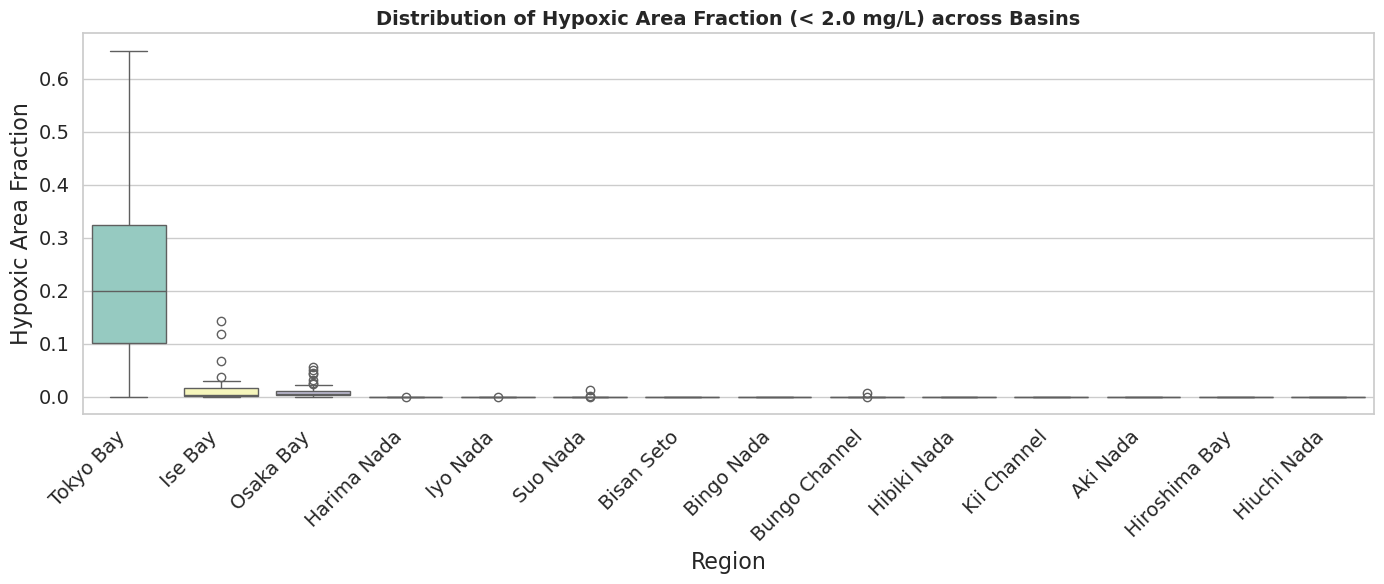

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
from scripts.mapping_config import MappingConfig

sns.set_theme(style="whitegrid", font_scale=1.5)
MappingConfig.apply_global_plot_styles() # Re-apply to overwrite seaborn defaults
plt.rcParams.update({"figure.autolayout": True, "xtick.labelsize": 14, "ytick.labelsize": 14, "axes.labelsize": 16})

# 3.1 Distribution Box Plots
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_fractions, x='Region', y='Hypoxic_Fraction', palette="Set3")
plt.xticks(rotation=45, ha='right')
plt.title(f"Distribution of Hypoxic Area Fraction (< {HYPOXIA_THRESHOLD} mg/L) across Basins")
plt.ylabel("Hypoxic Area Fraction")
plt.tight_layout()
plt.show()

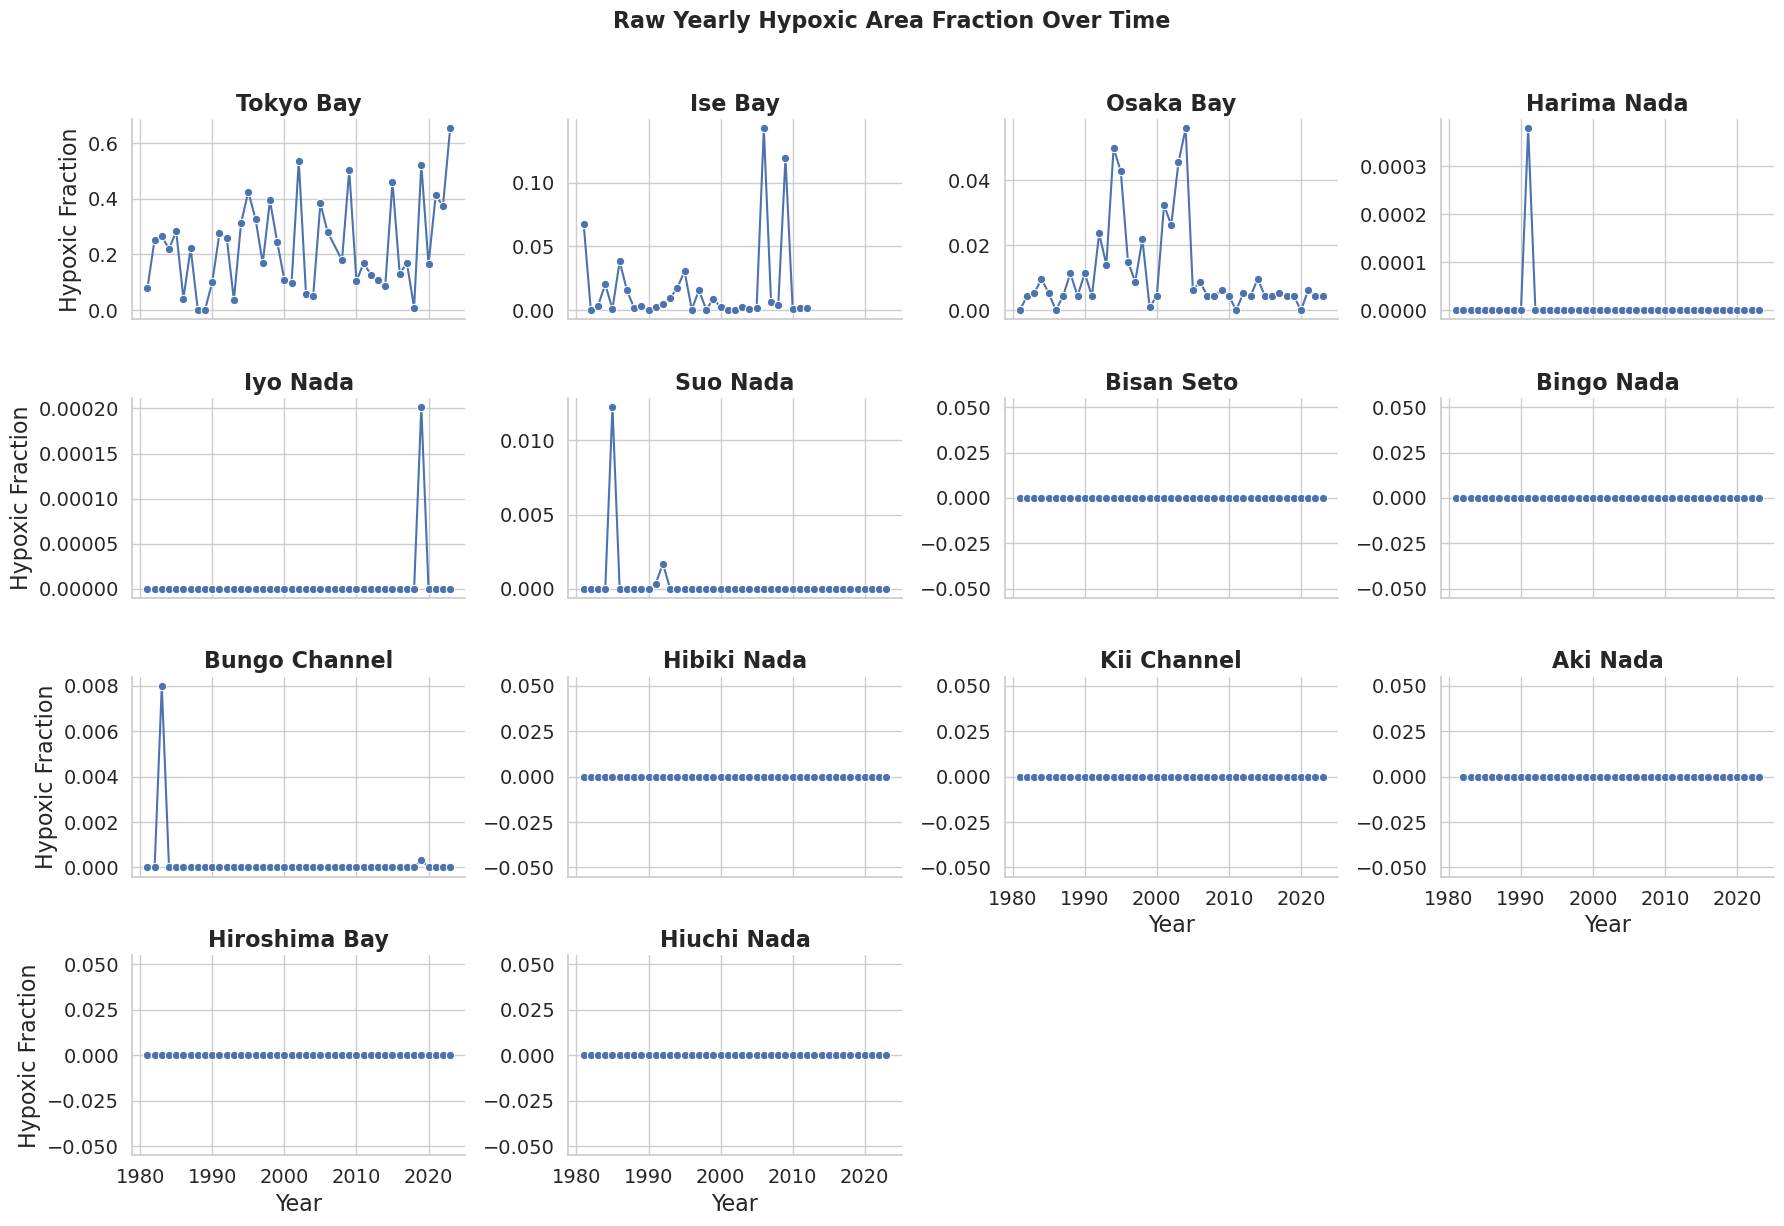

In [6]:
# 3.2 Time-Series Line Plots
g = sns.FacetGrid(df_fractions, col="Region", col_wrap=4, height=3, aspect=1.5, sharey=False)
g.map(sns.lineplot, "Year", "Hypoxic_Fraction", marker="o")
g.set_axis_labels("Year", "Hypoxic Fraction")
g.set_titles("{col_name}")
plt.suptitle("Raw Yearly Hypoxic Area Fraction Over Time", y=1.02)
plt.tight_layout()
plt.show()

In [7]:
# 3.3 Summary Statistics Table
summary_stats = df_fractions.groupby('Region')['Hypoxic_Fraction'].agg(
    ['mean', 'median', 'min', 'max', 'std', 'count']
).reset_index()
summary_stats.sort_values('median', ascending=False, inplace=True)
summary_stats.style.format(precision=3).background_gradient(cmap='Reds', subset=['mean', 'median', 'max'])

,Region,mean,median,min,max,std,count
13,Tokyo Bay,0.229,0.200,0.000,0.653,0.164,42
11,Osaka Bay,0.011,0.005,0.000,0.056,0.014,43
8,Ise Bay,0.016,0.003,0.000,0.143,0.033,32
2,Bisan Seto,0.000,0.000,0.000,0.000,0.000,43
0,Aki Nada,0.000,0.000,0.000,0.000,0.000,42
1,Bingo Nada,0.000,0.000,0.000,0.000,0.000,43
5,Hibiki Nada,0.000,0.000,0.000,0.000,0.000,43
4,Harima Nada,0.000,0.000,0.000,0.000,0.000,43
3,Bungo Channel,0.000,0.000,0.000,0.008,0.001,43
6,Hiroshima Bay,0.000,0.000,0.000,0.000,0.000,43


## 4. Temporal Smoothing & Trend Analysis

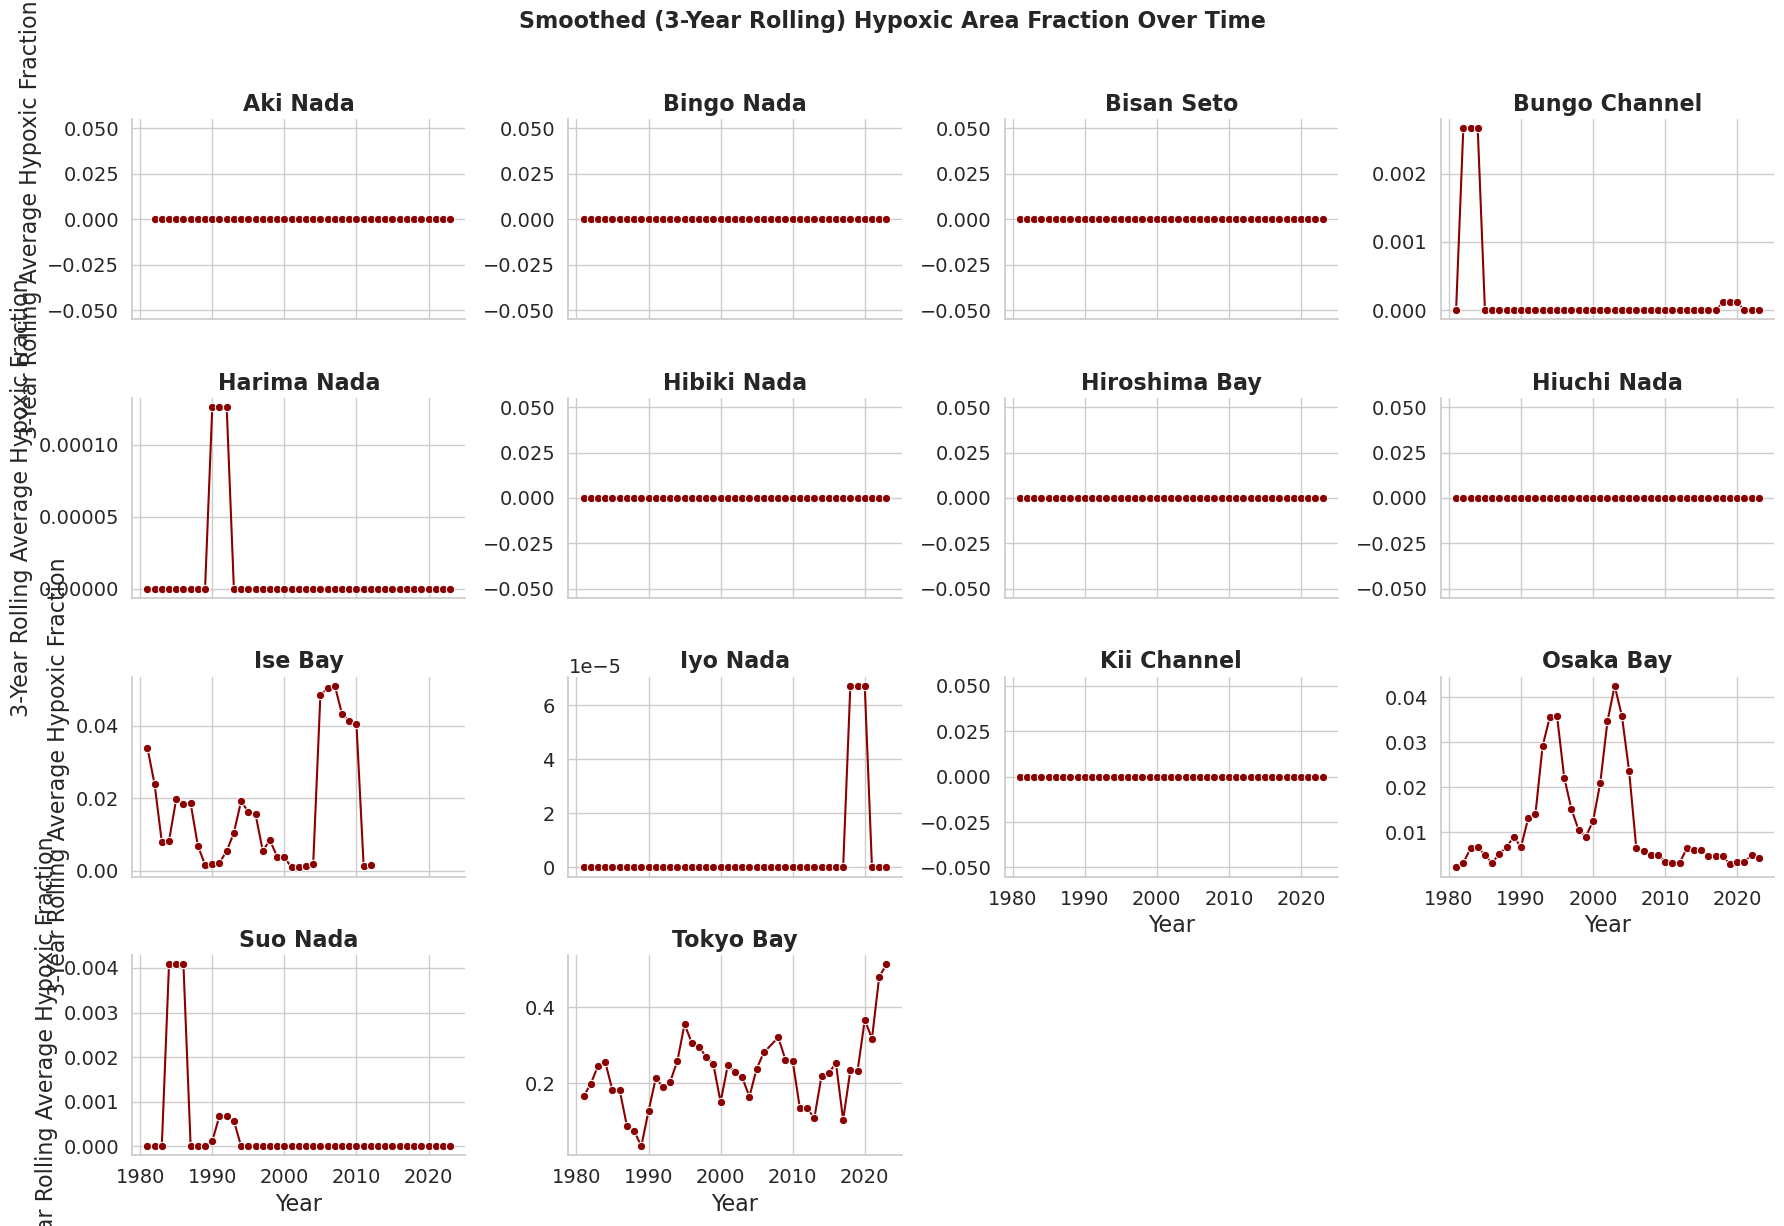

In [8]:
# 4.1 Apply 3-year rolling average
df_fractions.sort_values(['Region', 'Year'], inplace=True)
df_fractions['Smoothed_Fraction'] = df_fractions.groupby('Region')['Hypoxic_Fraction'].transform(
    lambda x: x.rolling(window=3, min_periods=1, center=True).mean()
)

# 4.2 Smoothed Time-Series Plots
g_smooth = sns.FacetGrid(df_fractions, col="Region", col_wrap=4, height=3, aspect=1.5, sharey=False)
g_smooth.map(sns.lineplot, "Year", "Smoothed_Fraction", marker="o", color='darkred')
g_smooth.set_axis_labels("Year", "3-Year Rolling Average Hypoxic Fraction")
g_smooth.set_titles("{col_name}")
plt.suptitle("Smoothed (3-Year Rolling) Hypoxic Area Fraction Over Time", y=1.02)
plt.tight_layout()
plt.show()

In [9]:
# 4.3 Trend Table using linear regression
trend_records = []
for region, group in df_fractions.groupby('Region'):
    # Need sufficient years to calculate trend
    valid_group = group.dropna(subset=['Smoothed_Fraction'])
    if len(valid_group) < 5:
        continue
        
    # Raw trend
    slope_raw, int_raw, r_raw, p_raw, err_raw = stats.linregress(group['Year'], group['Hypoxic_Fraction'])
    # Smoothed trend
    slope_smooth, int_smooth, r_smooth, p_smooth, err_smooth = stats.linregress(valid_group['Year'], valid_group['Smoothed_Fraction'])
    
    trend_records.append({
        'Region': region,
        'Raw_Slope': slope_raw,
        'Raw_P-value': p_raw,
        'Smoothed_Slope': slope_smooth,
        'Smoothed_P-value': p_smooth
    })
    
trend_df = pd.DataFrame(trend_records)
trend_df.sort_values('Smoothed_Slope', ascending=False, inplace=True)
trend_df.style.format(precision=4).background_gradient(cmap='vlag', subset=['Raw_Slope', 'Smoothed_Slope'])

,Region,Raw_Slope,Raw_P-value,Smoothed_Slope,Smoothed_P-value
13,Tokyo Bay,0.0035,0.0870,0.0032,0.0054
8,Ise Bay,0.0004,0.5789,0.0004,0.1763
9,Iyo Nada,0.0000,0.1736,0.0000,0.0132
2,Bisan Seto,0.0000,1.0000,0.0000,1.0000
0,Aki Nada,0.0000,1.0000,0.0000,1.0000
1,Bingo Nada,0.0000,1.0000,0.0000,1.0000
6,Hiroshima Bay,0.0000,1.0000,0.0000,1.0000
10,Kii Channel,0.0000,1.0000,0.0000,1.0000
5,Hibiki Nada,0.0000,1.0000,0.0000,1.0000
7,Hiuchi Nada,0.0000,1.0000,0.0000,1.0000
